# SAMS Vibration: UCI accelerometer anomaly training

This notebook trains the window classifier that SAMS uses for machine vibration state. The live service (`monitoring/services/vibration_inference.py`) loads `models/vibration/vib_exp02_xgboost/model.joblib` when present, then falls back to the random forest experiment. It expects exactly 48 handcrafted features per 2 s window at 50 Hz. This notebook writes each experiment under its id and copies the validation winner to `models/vibration/best/model.joblib` plus `metadata.json`.

## Labels (UCI id=846)

| wconfid | SAMS label |
|---------|------------|
| 1 | NORMAL |
| 2 or 3 | ABNORMAL |

## Experiments

| Id | Model | Input |
|----|-------|-------|
| vib_exp01_random_forest | Random Forest | 48 window features |
| vib_exp02_xgboost | XGBoost | 48 window features |
| vib_exp03_svm_rbf | SVM RBF | scaled 48 features |
| vib_exp04_1dcnn | 1D CNN | raw X/Y/Z windows |

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, feature list, helpers |
| 1 | Download UCI Accelerometer dataset |
| 2 | Exploratory data analysis and signal previews |
| 3 | Sliding windows, feature extraction, PCA |
| 4 | Split by fan speed (`pctid`) holdout |
| 5 | Hyperparameter tables and training utilities |
| 6 | Experiments |
| 7 | Compare experiments, promote best, model card |
| 8 | Limitations |

## Rules

1. Splits hold out entire `pctid` values so overlapping windows from the same run do not leak.
2. Feature names match the live service list exactly.
3. Every table is a pandas DataFrame with `display()` and a CSV under `RESULTS_DIR`. Every chart is saved as PNG.
4. There are no optional run flags; the full pipeline executes top to bottom.

## 0. Setup

### 0.1 Paths

The notebook runs in Google Colab or locally. In Colab, data lives on fast local disk (`/content/SAMS`) and models plus results on Google Drive.

In [1]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "vibration" / "accelerometer",
    SAMS_ROOT / "models" / "vibration",
    SAMS_ROOT / "results" / "vibration",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("SAMS_ROOT:", SAMS_ROOT.resolve())

Running in Colab: True
SAMS_ROOT: /content/SAMS


In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vibration"
RESULTS_DIR = DRIVE_ROOT / "results" / "vibration"
DATA_DIR = SAMS_ROOT / "datasets" / "vibration" / "accelerometer"

for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:   ", DATA_DIR)

Mounted at /content/drive
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/vibration
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vibration
DATA_DIR:    /content/SAMS/datasets/vibration/accelerometer


### 0.2 Packages

In [3]:
import subprocess
import sys

PACKAGES = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "joblib",
    "tqdm",
    "xgboost",
    "torch",
]

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    print("Packages installed.")
else:
    print("Not in Colab. Install these packages if an import fails:")
    print(PACKAGES)

Packages installed.


In [4]:
import gc
import json
import time
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from scipy.stats import kurtosis, skew
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

### 0.3 Configuration

Every setting that changes the result is listed here with its meaning. Change a value and rerun from this cell downward.

In [5]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

SAMPLE_RATE_HZ = 50.0
WINDOW_SIZE = 100
WINDOW_STRIDE = 50
UCI_DATASET_ID = 846

CLASS_NAMES = ["NORMAL", "ABNORMAL"]

MAX_EPOCHS_CNN = 40
CNN_PATIENCE = 8
CNN_BATCH = 64
CNN_LR = 1e-3

config_rows = [
    {"setting": "SEED", "value": SEED, "meaning": "Random seed for splits and training"},
    {"setting": "SAMPLE_RATE_HZ", "value": SAMPLE_RATE_HZ, "meaning": "Assumed sampling rate (matches live service)"},
    {"setting": "WINDOW_SIZE", "value": WINDOW_SIZE, "meaning": "Samples per window (2.0 s at 50 Hz)"},
    {"setting": "WINDOW_STRIDE", "value": WINDOW_STRIDE, "meaning": "Stride between windows (50 percent overlap)"},
    {"setting": "UCI_DATASET_ID", "value": UCI_DATASET_ID, "meaning": "UCI ML repository Accelerometer dataset id"},
    {"setting": "MAX_EPOCHS_CNN", "value": MAX_EPOCHS_CNN, "meaning": "Upper epoch limit for the 1D CNN"},
    {"setting": "CNN_PATIENCE", "value": CNN_PATIENCE, "meaning": "Early stopping patience on validation macro-F1 for CNN"},
    {"setting": "CNN_BATCH", "value": CNN_BATCH, "meaning": "Batch size for CNN training"},
    {"setting": "CNN_LR", "value": CNN_LR, "meaning": "Adam learning rate for CNN"},
]
config_table = pd.DataFrame(config_rows).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

,value,meaning
setting,,
SEED,42.000,Random seed for splits and training
SAMPLE_RATE_HZ,50.000,Assumed sampling rate (matches live service)
WINDOW_SIZE,100.000,Samples per window (2.0 s at 50 Hz)
WINDOW_STRIDE,50.000,Stride between windows (50 percent overlap)
UCI_DATASET_ID,846.000,UCI ML repository Accelerometer dataset id
MAX_EPOCHS_CNN,40.000,Upper epoch limit for the 1D CNN
CNN_PATIENCE,8.000,Early stopping patience on validation macro-F1...
CNN_BATCH,64.000,Batch size for CNN training
CNN_LR,0.001,Adam learning rate for CNN


### 0.4 Live feature columns

These names are copied verbatim from `monitoring/services/vibration_inference.py`. The live service builds a row in this order.

In [6]:
FEATURE_COLS = [
    "x_mean", "x_std", "x_rms", "x_max", "x_min", "x_ptp", "x_energy", "x_var",
    "x_kurtosis", "x_skew", "x_dom_freq", "x_dom_amp",
    "y_mean", "y_std", "y_rms", "y_max", "y_min", "y_ptp", "y_energy", "y_var",
    "y_kurtosis", "y_skew", "y_dom_freq", "y_dom_amp",
    "z_mean", "z_std", "z_rms", "z_max", "z_min", "z_ptp", "z_energy", "z_var",
    "z_kurtosis", "z_skew", "z_dom_freq", "z_dom_amp",
    "mag_mean", "mag_std", "mag_rms", "mag_max", "mag_min", "mag_ptp", "mag_energy",
    "mag_var", "mag_kurtosis", "mag_skew", "mag_dom_freq", "mag_dom_amp",
]

assert len(FEATURE_COLS) == 48
feature_table = pd.DataFrame({"index": range(len(FEATURE_COLS)), "feature": FEATURE_COLS})
display(feature_table)
feature_table.to_csv(RESULTS_DIR / "feature_cols.csv", index=False)

,index,feature
0,0,x_mean
1,1,x_std
2,2,x_rms
3,3,x_max
4,4,x_min
5,5,x_ptp
6,6,x_energy
7,7,x_var
8,8,x_kurtosis
9,9,x_skew


### 0.5 Helper functions

In [7]:
def save_table(frame: pd.DataFrame, name: str) -> Path:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)
    return path


def confusion_df(y_true, y_pred, labels=None) -> pd.DataFrame:
    labels = labels or list(range(len(CLASS_NAMES)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    return pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist(),
        "classification_report": classification_report(
            y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0
        ),
    }


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")


print("Helpers ready.")

Helpers ready.


## 1. Download UCI Accelerometer data

We fetch UCI dataset 846 (Accelerometer). Columns include `wconfid`, `pctid`, and raw `x`, `y`, `z` acceleration.

In [9]:
import urllib.request
import zipfile

zip_path = DATA_DIR / "uci_846.zip"
if not zip_path.exists():
    url = "https://archive.ics.uci.edu/static/public/846/accelerometer.zip"
    print("Downloading", url)
    urllib.request.urlretrieve(url, zip_path)
else:
    print("Using cached", zip_path)

extract_dir = DATA_DIR / "uci_raw"
csv_files = sorted(extract_dir.rglob("*.csv")) if extract_dir.exists() else []
if not csv_files:
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    print("Extracted to", extract_dir)
    csv_files = sorted(extract_dir.rglob("*.csv"))
else:
    print("Raw CSV already present")

if not csv_files:
    raise FileNotFoundError(f"No CSV found in {extract_dir}")
raw_csv = csv_files[0]
print("Reading", raw_csv.name)

raw_df = pd.read_csv(raw_csv)
raw_df["sample_idx"] = np.arange(len(raw_df))
raw_path = DATA_DIR / "accelerometer_raw.csv"
raw_df.to_csv(raw_path, index=False)
print("Rows:", len(raw_df))
display(raw_df.head())
save_table(raw_df.describe().T, "raw_summary")

Extracted to /content/SAMS/datasets/vibration/accelerometer/uci_raw
Reading accelerometer (1).csv
Rows: 153000


,wconfid,pctid,x,y,z,sample_idx
0,1,20,1.004,0.090,-0.125,0
1,1,20,1.004,-0.043,-0.125,1
2,1,20,0.969,0.090,-0.121,2
3,1,20,0.973,-0.012,-0.137,3
4,1,20,1.000,-0.016,-0.121,4


,count,mean,std,min,25%,50%,75%,max
wconfid,153000.0,2.000000,0.816499,1.000,1.000,2.000,3.000,3.000
pctid,153000.0,60.000000,24.494977,20.000,40.000,60.000,80.000,100.000
x,153000.0,0.995622,0.773958,-8.000,0.945,0.992,1.039,7.996
y,153000.0,0.005351,0.742602,-8.000,-0.078,0.008,0.105,7.996
z,153000.0,-0.117769,0.517008,-5.867,-0.172,-0.125,-0.066,6.086
sample_idx,153000.0,76499.500000,44167.439930,0.000,38249.750,76499.500,114749.250,152999.000


PosixPath('/content/drive/MyDrive/SAMS/results/vibration/raw_summary.csv')

## 2. Exploratory data analysis

We map `wconfid` to binary labels, inspect class balance across fan speeds (`pctid`), and plot short magnitude traces per class.

,count
label_name,
NORMAL,51000
ABNORMAL,102000


label_name,NORMAL,ABNORMAL
pctid,,
20,3000,6000
25,3000,6000
30,3000,6000
35,3000,6000
40,3000,6000
45,3000,6000
50,3000,6000
55,3000,6000
60,3000,6000


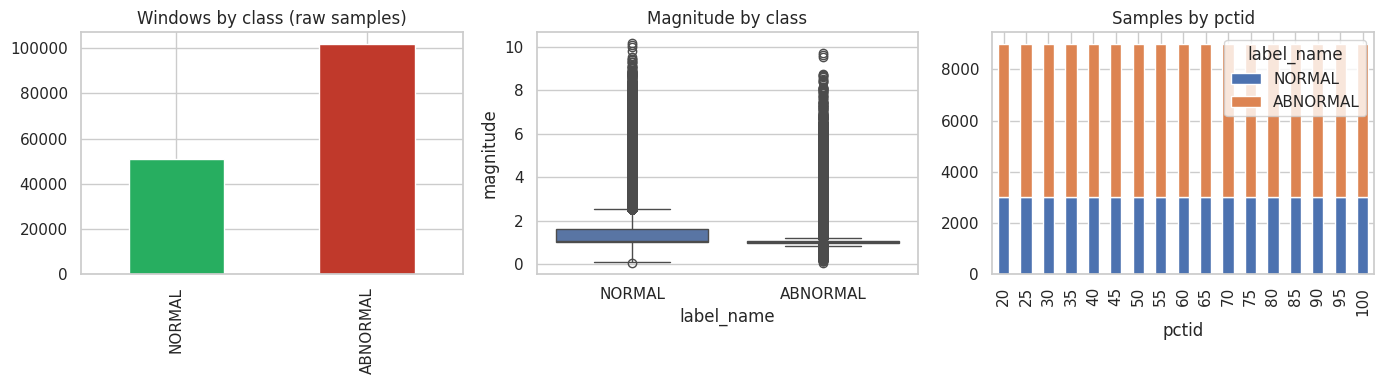

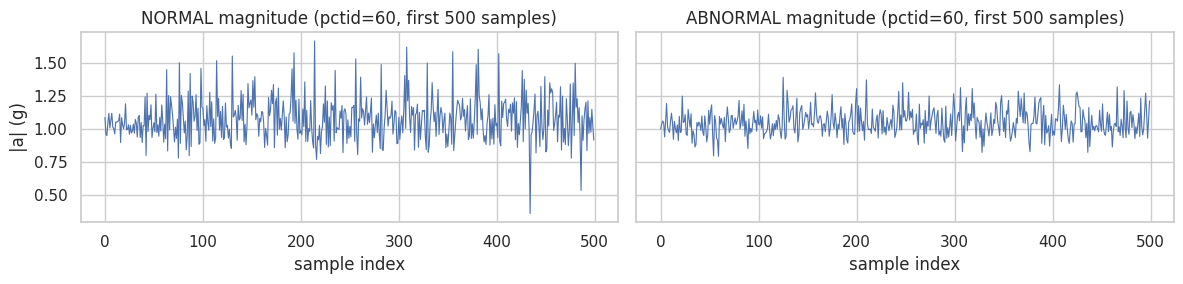

In [10]:
df = raw_df.copy()
df["label"] = df["wconfid"].apply(lambda v: 0 if int(v) == 1 else 1)
df["label_name"] = df["label"].map(dict(enumerate(CLASS_NAMES)))
df["magnitude"] = np.sqrt(df["x"] ** 2 + df["y"] ** 2 + df["z"] ** 2)

label_counts = df["label_name"].value_counts().reindex(CLASS_NAMES)
save_table(label_counts.to_frame("count"), "eda_label_counts")

pct_counts = pd.crosstab(df["pctid"], df["label_name"]).reindex(columns=CLASS_NAMES, fill_value=0)
save_table(pct_counts, "eda_pctid_by_label")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
label_counts.plot(kind="bar", ax=axes[0], color=["#27ae60", "#c0392b"])
axes[0].set_title("Windows by class (raw samples)")
axes[0].set_xlabel("")
sns.boxplot(data=df, x="label_name", y="magnitude", order=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Magnitude by class")
pct_counts.plot(kind="bar", stacked=True, ax=axes[2])
axes[2].set_title("Samples by pctid")
axes[2].set_xlabel("pctid")
plt.tight_layout()
preview_path = RESULTS_DIR / "eda_overview.png"
plt.savefig(preview_path, dpi=140)
plt.show()

demo_pct = sorted(df["pctid"].unique())[len(df["pctid"].unique()) // 2]
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, name in zip(axes, CLASS_NAMES):
    sub = df[(df["label_name"] == name) & (df["pctid"] == demo_pct)].head(500)
    ax.plot(sub["magnitude"].values, linewidth=0.8)
    ax.set_title(f"{name} magnitude (pctid={demo_pct}, first 500 samples)")
    ax.set_xlabel("sample index")
axes[0].set_ylabel("|a| (g)")
plt.tight_layout()
sig_path = RESULTS_DIR / "signal_previews_by_class.png"
plt.savefig(sig_path, dpi=140)
plt.show()

## 3. Sliding windows and features

Windows slide over each `(wconfid, pctid)` run. Only windows with a single label are kept. Features follow the same recipe as the live service (`window_to_features`).

In [11]:
def _axis_features(sig: np.ndarray, prefix: str) -> Dict[str, float]:
    sig = sig.astype(np.float64)
    rms = float(np.sqrt(np.mean(sig ** 2)))
    n = len(sig)
    fft = np.fft.rfft(sig - sig.mean())
    freqs = np.fft.rfftfreq(n, d=1.0 / SAMPLE_RATE_HZ)
    mag = np.abs(fft)
    if len(mag) > 1:
        dom_idx = 1 + int(np.argmax(mag[1:]))
        dom_freq = float(freqs[dom_idx])
        dom_amp = float(mag[dom_idx])
    else:
        dom_freq, dom_amp = 0.0, 0.0
    return {
        f"{prefix}_mean": float(sig.mean()),
        f"{prefix}_std": float(sig.std()),
        f"{prefix}_rms": rms,
        f"{prefix}_max": float(sig.max()),
        f"{prefix}_min": float(sig.min()),
        f"{prefix}_ptp": float(np.ptp(sig)),
        f"{prefix}_energy": float(np.sum(sig ** 2)),
        f"{prefix}_var": float(sig.var()),
        f"{prefix}_kurtosis": float(kurtosis(sig, fisher=True, bias=False)),
        f"{prefix}_skew": float(skew(sig, bias=False)),
        f"{prefix}_dom_freq": dom_freq,
        f"{prefix}_dom_amp": dom_amp,
    }


def build_windows(frame: pd.DataFrame) -> Tuple[pd.DataFrame, np.ndarray]:
    feature_rows: List[Dict[str, Any]] = []
    raw_windows: List[np.ndarray] = []
    groups = frame.groupby(["wconfid", "pctid"], sort=True)
    for (wconfid, pctid), g in tqdm(groups, desc="Windowing"):
        g = g.sort_values("sample_idx")
        xyz = g[["x", "y", "z"]].to_numpy(dtype=np.float32)
        labels = g["label"].to_numpy()
        n = len(g)
        if n < WINDOW_SIZE:
            continue
        for start in range(0, n - WINDOW_SIZE + 1, WINDOW_STRIDE):
            end = start + WINDOW_SIZE
            win = xyz[start:end]
            win_labels = labels[start:end]
            if len(np.unique(win_labels)) != 1:
                continue
            label = int(win_labels[0])
            mag = np.sqrt(np.sum(win ** 2, axis=1))
            feats: Dict[str, Any] = {
                "wconfid": int(wconfid),
                "pctid": int(pctid),
                "start": int(start),
                "label": label,
                "label_name": CLASS_NAMES[label],
            }
            for i, axis in enumerate(["x", "y", "z"]):
                feats.update(_axis_features(win[:, i], axis))
            feats.update(_axis_features(mag, "mag"))
            feature_rows.append(feats)
            raw_windows.append(win)
    feat_df = pd.DataFrame(feature_rows)
    raw_arr = np.stack(raw_windows, axis=0) if raw_windows else np.empty((0, WINDOW_SIZE, 3), dtype=np.float32)
    return feat_df, raw_arr


feat_df, raw_windows = build_windows(df)
print("Windows:", len(feat_df), "| raw shape:", raw_windows.shape)
display(feat_df.head())

missing = [c for c in FEATURE_COLS if c not in feat_df.columns]
if missing:
    raise RuntimeError("Missing expected features: " + ", ".join(missing))

feat_path = DATA_DIR / "uci_window_features.csv"
feat_df.to_csv(feat_path, index=False)
np.save(DATA_DIR / "uci_raw_windows.npy", raw_windows)
save_table(feat_df["label_name"].value_counts().reindex(CLASS_NAMES).to_frame("windows"), "window_label_counts")

Windowing:   0%|          | 0/51 [00:00<?, ?it/s]

Windows: 3009 | raw shape: (3009, 100, 3)


,wconfid,pctid,start,label,label_name,x_mean,x_std,x_rms,x_max,x_min,x_ptp,x_energy,x_var,x_kurtosis,x_skew,x_dom_freq,x_dom_amp,y_mean,y_std,y_rms,y_max,y_min,y_ptp,y_energy,y_var,...,y_dom_amp,z_mean,z_std,z_rms,z_max,z_min,z_ptp,z_energy,z_var,z_kurtosis,z_skew,z_dom_freq,z_dom_amp,mag_mean,mag_std,mag_rms,mag_max,mag_min,mag_ptp,mag_energy,mag_var,mag_kurtosis,mag_skew,mag_dom_freq,mag_dom_amp
0,1,20,0,0,NORMAL,0.99273,0.020690,0.992946,1.047,0.957,0.090,98.594089,0.000428,-0.527121,0.458639,16.5,0.668846,-0.00249,0.078101,0.078140,0.148,-0.156,0.304,0.610593,0.006100,...,2.687449,-0.12998,0.012132,0.130545,-0.105,-0.164,0.059,1.704198,0.000147,-0.320511,-0.545902,18.5,0.361549,1.004339,0.019808,1.004534,1.053202,0.964794,0.088408,100.908881,0.000392,-0.447906,0.460499,16.5,0.592981
1,1,20,50,0,NORMAL,0.99416,0.021495,0.994392,1.047,0.957,0.090,98.881613,0.000462,-0.758760,0.333548,16.5,0.626893,-0.00650,0.078994,0.079261,0.148,-0.152,0.300,0.628224,0.006240,...,2.508616,-0.13076,0.012385,0.131345,-0.105,-0.156,0.051,1.725156,0.000153,-0.706908,-0.476309,18.5,0.353820,1.005947,0.020484,1.006156,1.053202,0.964794,0.088408,101.234992,0.000420,-0.671674,0.338822,16.5,0.517780
2,1,20,100,0,NORMAL,0.99552,0.021300,0.995748,1.039,0.957,0.082,99.151377,0.000454,-0.960323,0.242070,16.5,0.697718,-0.00519,0.082033,0.082197,0.148,-0.156,0.304,0.675633,0.006729,...,2.817629,-0.13095,0.011469,0.131451,-0.109,-0.156,0.047,1.727943,0.000132,-0.485452,-0.551212,16.5,0.314174,1.007547,0.019939,1.007745,1.052545,0.971435,0.081110,101.554952,0.000398,-0.856201,0.338484,16.5,0.600113
3,1,20,150,0,NORMAL,0.99387,0.022460,0.994124,1.039,0.953,0.086,98.828200,0.000504,-0.876254,0.333500,16.5,0.707502,-0.00129,0.081481,0.081491,0.148,-0.156,0.304,0.664077,0.006639,...,1.977792,-0.13044,0.011784,0.130971,-0.098,-0.160,0.062,1.715346,0.000139,-0.020452,-0.437550,17.5,0.303418,1.005799,0.021077,1.006020,1.051451,0.969979,0.081473,101.207623,0.000444,-0.759131,0.440977,16.5,0.602518
4,1,20,200,0,NORMAL,0.99418,0.023330,0.994454,1.047,0.938,0.109,98.893813,0.000544,-0.664287,0.192891,17.5,0.534980,-0.00455,0.077798,0.077931,0.141,-0.156,0.297,0.607321,0.006053,...,2.064452,-0.13127,0.012613,0.131875,-0.098,-0.160,0.062,1.739089,0.000159,-0.340656,-0.221207,18.5,0.322307,1.005934,0.022317,1.006182,1.060331,0.949354,0.110977,101.240223,0.000498,-0.427531,0.291774,17.5,0.553592


,windows
label_name,
NORMAL,1003
ABNORMAL,2006


PosixPath('/content/drive/MyDrive/SAMS/results/vibration/window_label_counts.csv')

### 3.1 PCA of window features

Two principal components of the scaled 48-D feature vectors, coloured by vibration class.

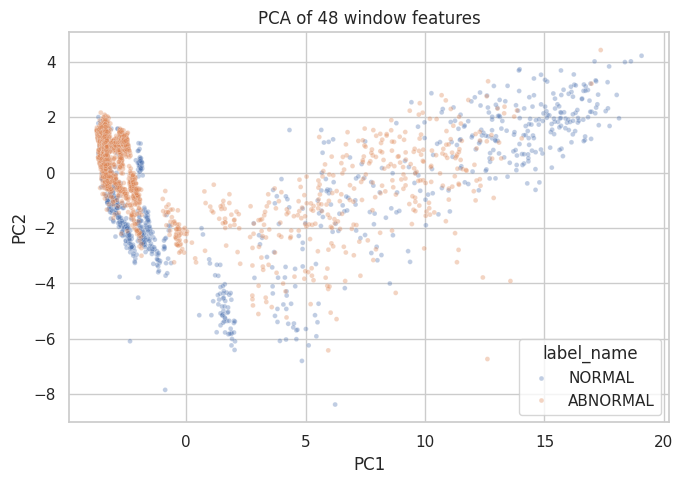

,component,explained_variance_ratio
0,PC1,0.666737
1,PC2,0.059943


PosixPath('/content/drive/MyDrive/SAMS/results/vibration/pca_explained_variance.csv')

In [12]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_all = feat_df[FEATURE_COLS].to_numpy(dtype=np.float32)
y_all = feat_df["label"].to_numpy()
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X_all)
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "label_name": feat_df["label_name"].values,
})
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label_name", hue_order=CLASS_NAMES, alpha=0.35, s=12, ax=ax)
ax.set_title("PCA of 48 window features")
plt.tight_layout()
pca_path = RESULTS_DIR / "pca_features_by_class.png"
plt.savefig(pca_path, dpi=140)
plt.show()
var_table = pd.DataFrame({"component": ["PC1", "PC2"], "explained_variance_ratio": pca.explained_variance_ratio_})
save_table(var_table, "pca_explained_variance")

## 4. Train / val / test split by pctid

Entire fan speeds are held out so the model must generalise across operating points, not memorise window overlap within one speed.

In [13]:
all_speeds = sorted(feat_df["pctid"].unique())
rng = np.random.default_rng(SEED)
shuffled = list(rng.permutation(all_speeds))
n = len(shuffled)
n_test = max(2, int(round(0.20 * n)))
n_val = max(2, int(round(0.15 * n)))
test_speeds = set(shuffled[:n_test])
val_speeds = set(shuffled[n_test : n_test + n_val])
train_speeds = set(shuffled[n_test + n_val :])

split_table = pd.DataFrame([
    {"split": "train", "pctid_list": sorted(train_speeds), "n_windows": int(feat_df["pctid"].isin(train_speeds).sum())},
    {"split": "val", "pctid_list": sorted(val_speeds), "n_windows": int(feat_df["pctid"].isin(val_speeds).sum())},
    {"split": "test", "pctid_list": sorted(test_speeds), "n_windows": int(feat_df["pctid"].isin(test_speeds).sum())},
])
save_table(split_table, "split_by_pctid")


def split_mask(speeds: set) -> np.ndarray:
    return feat_df["pctid"].isin(speeds).to_numpy()


train_m = split_mask(train_speeds)
val_m = split_mask(val_speeds)
test_m = split_mask(test_speeds)

X_train = feat_df.loc[train_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_train = feat_df.loc[train_m, "label"].to_numpy(dtype=np.int64)
X_val = feat_df.loc[val_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_val = feat_df.loc[val_m, "label"].to_numpy(dtype=np.int64)
X_test = feat_df.loc[test_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_test = feat_df.loc[test_m, "label"].to_numpy(dtype=np.int64)

W_train = raw_windows[train_m]
W_val = raw_windows[val_m]
W_test = raw_windows[test_m]

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}: n={len(yy):5d} | NORMAL={(yy==0).sum():4d} | ABNORMAL={(yy==1).sum():4d}")

,split,pctid_list,n_windows
0,train,"[20, 25, 30, 35, 40, 45, 55, 60, 85, 90, 95]",1947
1,val,"[50, 65, 70]",531
2,test,"[75, 80, 100]",531


train: n= 1947 | NORMAL= 649 | ABNORMAL=1298
val  : n=  531 | NORMAL= 177 | ABNORMAL= 354
test : n=  531 | NORMAL= 177 | ABNORMAL= 354


## 5. Experiment utilities

In [17]:
def to_json_safe(value):
    """Turn NumPy and pandas values into plain Python types that json can write."""
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


def save_sklearn_experiment(
    experiment_id: str,
    approach: str,
    model_obj: Any,
    metrics: Dict[str, Any],
    hyperparam_rows: List[Dict[str, Any]],
) -> Path:
    register_hyperparams(experiment_id, hyperparam_rows)
    out_dir = MODELS_DIR / experiment_id
    out_dir.mkdir(parents=True, exist_ok=True)
    model_path = out_dir / "model.joblib"
    joblib.dump(model_obj, model_path)
    meta = {
        "experiment_id": experiment_id,
        "approach": approach,
        "task": "vibration_anomaly",
        "dataset": f"uci_{UCI_DATASET_ID}",
        "class_names": CLASS_NAMES,
        "label_map": {"wconfid=1": "NORMAL", "wconfid=2|3": "ABNORMAL"},
        "sample_rate_hz": SAMPLE_RATE_HZ,
        "window_size": WINDOW_SIZE,
        "window_stride": WINDOW_STRIDE,
        "feature_cols": FEATURE_COLS,
        "split": {
            "strategy": "pctid_holdout",
            "train_pctid": sorted(train_speeds),
            "val_pctid": sorted(val_speeds),
            "test_pctid": sorted(test_speeds),
        },
        "test_metrics": {k: v for k, v in metrics.items() if k != "classification_report"},
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }
    meta_path = out_dir / "metadata.json"
    with open(meta_path, "w") as f:
        json.dump(meta, f, indent=2, default=to_json_safe)
    cm = np.array(metrics["confusion_matrix"])
    cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
    save_table(cm_df, f"confusion_{experiment_id}")
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
    plt.title(experiment_id)
    plt.tight_layout()
    plt.savefig(out_dir / "confusion_matrix.png", dpi=140)
    plt.show()
    row = {
        "experiment_id": experiment_id,
        "approach": approach,
        "val_f1_macro": metrics.get("val_f1_macro", np.nan),
        **{k: metrics[k] for k in ["accuracy", "f1_macro", "recall_macro", "precision_macro"] if k in metrics},
    }
    ledger_path = RESULTS_DIR / "vibration_experiment_ledger.csv"
    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        prev = prev[prev["experiment_id"] != experiment_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)
    print("[SAVE]", model_path)
    return out_dir


LEDGER_ROWS: List[Dict[str, Any]] = []

## 6. Experiments

Each experiment logs validation macro-F1 for model selection. Test metrics are computed once per experiment after training.

### 6.1 Experiment 1 - Random Forest

,value,meaning
parameter,,
n_estimators,400,Number of trees
max_depth,None,Unlimited depth
class_weight,balanced,Upweight minority class
random_state,42,Reproducibility


,value,meaning
parameter,,
n_estimators,400,Number of trees
max_depth,None,Unlimited depth
class_weight,balanced,Upweight minority class
random_state,42,Reproducibility


,NORMAL,ABNORMAL
NORMAL,76,101
ABNORMAL,12,342


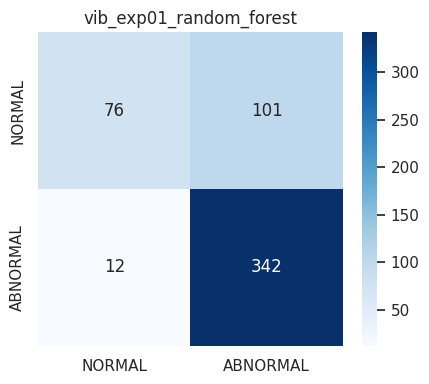

[SAVE] /content/drive/MyDrive/SAMS/models/vibration/vib_exp01_random_forest/model.joblib


In [18]:
exp_id = "vib_exp01_random_forest"
register_hyperparams(exp_id, [
    {"parameter": "n_estimators", "value": 400, "meaning": "Number of trees"},
    {"parameter": "max_depth", "value": "None", "meaning": "Unlimited depth"},
    {"parameter": "class_weight", "value": "balanced", "meaning": "Upweight minority class"},
    {"parameter": "random_state", "value": SEED, "meaning": "Reproducibility"},
])
rf = RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=SEED, n_jobs=-1)
t0 = time.time()
rf.fit(X_train, y_train)
val_pred = rf.predict(X_val)
val_m = compute_metrics(y_val, val_pred)
test_pred = rf.predict(X_test)
test_m = compute_metrics(y_test, test_pred)
test_m["val_f1_macro"] = val_m["f1_macro"]
test_m["train_sec"] = time.time() - t0
save_sklearn_experiment(exp_id, "Classical baseline - Random Forest on window features", rf, test_m, HYPERPARAMS[exp_id].to_dict("records"))
LEDGER_ROWS.append({"experiment_id": exp_id, "approach": "Random Forest", "val_f1_macro": val_m["f1_macro"], **test_m})

### 6.2 Experiment 2 - XGBoost

,value,meaning
parameter,,
n_estimators,300.00,Boosting rounds
max_depth,6.00,Tree depth
learning_rate,0.08,Shrinkage
subsample,0.90,Row subsample
scale_pos_weight,0.50,Balance ABNORMAL vs NORMAL


,value,meaning
parameter,,
n_estimators,300.00,Boosting rounds
max_depth,6.00,Tree depth
learning_rate,0.08,Shrinkage
subsample,0.90,Row subsample
scale_pos_weight,0.50,Balance ABNORMAL vs NORMAL


,NORMAL,ABNORMAL
NORMAL,152,25
ABNORMAL,48,306


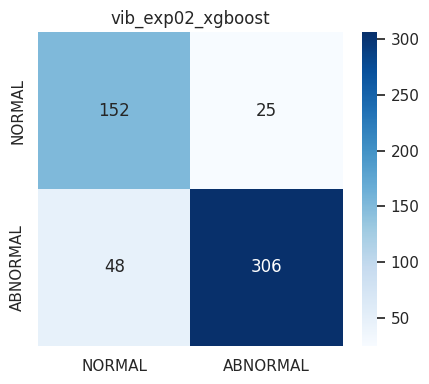

[SAVE] /content/drive/MyDrive/SAMS/models/vibration/vib_exp02_xgboost/model.joblib


,importance
mag_rms,0.132438
z_rms,0.115737
z_ptp,0.094693
y_mean,0.074846
y_skew,0.062240
x_ptp,0.052236
y_std,0.048353
z_mean,0.043351
mag_mean,0.038010
x_std,0.030357


PosixPath('/content/drive/MyDrive/SAMS/results/vibration/feature_importance_vib_exp02_xgboost.csv')

In [19]:
exp_id = "vib_exp02_xgboost"
register_hyperparams(exp_id, [
    {"parameter": "n_estimators", "value": 300, "meaning": "Boosting rounds"},
    {"parameter": "max_depth", "value": 6, "meaning": "Tree depth"},
    {"parameter": "learning_rate", "value": 0.08, "meaning": "Shrinkage"},
    {"parameter": "subsample", "value": 0.9, "meaning": "Row subsample"},
    {"parameter": "scale_pos_weight", "value": float((y_train == 0).sum() / max(1, (y_train == 1).sum())), "meaning": "Balance ABNORMAL vs NORMAL"},
])
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    scale_pos_weight=float((y_train == 0).sum() / max(1, (y_train == 1).sum())),
    n_jobs=-1,
)
t0 = time.time()
xgb.fit(X_train, y_train)
val_pred = xgb.predict(X_val)
val_m = compute_metrics(y_val, val_pred)
test_pred = xgb.predict(X_test)
test_m = compute_metrics(y_test, test_pred)
test_m["val_f1_macro"] = val_m["f1_macro"]
test_m["train_sec"] = time.time() - t0
save_sklearn_experiment(exp_id, "Boosted trees - XGBoost on window features", xgb, test_m, HYPERPARAMS[exp_id].to_dict("records"))
imp = pd.Series(xgb.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False).head(15)
save_table(imp.to_frame("importance"), f"feature_importance_{exp_id}")

### 6.3 Experiment 3 - SVM RBF

,value,meaning
parameter,,
kernel,rbf,Non-linear decision boundary
C,10.0,Regularisation strength
gamma,scale,RBF width
class_weight,balanced,Upweight minority class


,value,meaning
parameter,,
kernel,rbf,Non-linear decision boundary
C,10.0,Regularisation strength
gamma,scale,RBF width
class_weight,balanced,Upweight minority class


,NORMAL,ABNORMAL
NORMAL,116,61
ABNORMAL,29,325


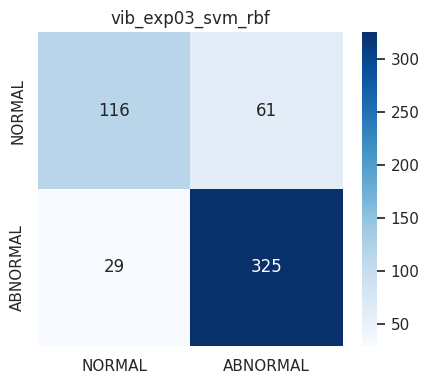

[SAVE] /content/drive/MyDrive/SAMS/models/vibration/vib_exp03_svm_rbf/model.joblib


PosixPath('/content/drive/MyDrive/SAMS/models/vibration/vib_exp03_svm_rbf')

In [20]:
exp_id = "vib_exp03_svm_rbf"
register_hyperparams(exp_id, [
    {"parameter": "kernel", "value": "rbf", "meaning": "Non-linear decision boundary"},
    {"parameter": "C", "value": 10.0, "meaning": "Regularisation strength"},
    {"parameter": "gamma", "value": "scale", "meaning": "RBF width"},
    {"parameter": "class_weight", "value": "balanced", "meaning": "Upweight minority class"},
])
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", C=10.0, gamma="scale", class_weight="balanced", random_state=SEED)),
])
t0 = time.time()
svm.fit(X_train, y_train)
val_pred = svm.predict(X_val)
val_m = compute_metrics(y_val, val_pred)
test_pred = svm.predict(X_test)
test_m = compute_metrics(y_test, test_pred)
test_m["val_f1_macro"] = val_m["f1_macro"]
test_m["train_sec"] = time.time() - t0
save_sklearn_experiment(exp_id, "Margin classifier - SVM RBF on scaled window features", svm, test_m, HYPERPARAMS[exp_id].to_dict("records"))

### 6.4 Experiment 4 - 1D CNN with early stopping

Raw windows are z-scored per window across time. Training stops when validation macro-F1 fails to improve for `CNN_PATIENCE` epochs.

In [21]:
class Conv1DWindow(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(3, 32, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        return self.net(x)


def normalize_windows(windows: np.ndarray) -> np.ndarray:
    mu = windows.mean(axis=1, keepdims=True)
    sd = windows.std(axis=1, keepdims=True) + 1e-6
    return (windows - mu) / sd


def make_loader(windows, labels, batch_size, shuffle):
    w = normalize_windows(windows)
    ds = TensorDataset(torch.from_numpy(w), torch.from_numpy(labels))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader = make_loader(W_train, y_train.astype(np.int64), CNN_BATCH, True)
val_loader = make_loader(W_val, y_val.astype(np.int64), CNN_BATCH, False)
test_loader = make_loader(W_test, y_test.astype(np.int64), CNN_BATCH, False)

exp_id = "vib_exp04_1dcnn"
register_hyperparams(exp_id, [
    {"parameter": "architecture", "value": "Conv1D x2 + linear", "meaning": "Lightweight temporal CNN"},
    {"parameter": "optimizer", "value": "Adam", "meaning": "First-order solver"},
    {"parameter": "lr", "value": CNN_LR, "meaning": "Learning rate"},
    {"parameter": "max_epochs", "value": MAX_EPOCHS_CNN, "meaning": "Upper epoch cap"},
    {"parameter": "patience", "value": CNN_PATIENCE, "meaning": "Early stopping on val macro-F1"},
])

model = Conv1DWindow().to(device)
opt = torch.optim.Adam(model.parameters(), lr=CNN_LR)
loss_fn = nn.CrossEntropyLoss()
best_f1 = -1.0
best_state = None
bad_epochs = 0
history = []

for epoch in range(1, MAX_EPOCHS_CNN + 1):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
    model.eval()
    preds, ys = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            logits = model(xb.to(device))
            preds.append(logits.argmax(1).cpu().numpy())
            ys.append(yb.numpy())
    y_pred = np.concatenate(preds)
    y_true = np.concatenate(ys)
    val_metrics = compute_metrics(y_true, y_pred)
    history.append({"epoch": epoch, "val_f1_macro": val_metrics["f1_macro"]})
    print(f"epoch {epoch:02d} val_f1_macro={val_metrics['f1_macro']:.4f}")
    if val_metrics["f1_macro"] > best_f1:
        best_f1 = val_metrics["f1_macro"]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= CNN_PATIENCE:
            print("Early stopping")
            break

if best_state is not None:
    model.load_state_dict(best_state)

model.eval()
preds, ys = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb.to(device))
        preds.append(logits.argmax(1).cpu().numpy())
        ys.append(yb.numpy())
test_m = compute_metrics(np.concatenate(ys), np.concatenate(preds))
test_m["val_f1_macro"] = best_f1

out_dir = MODELS_DIR / exp_id
out_dir.mkdir(parents=True, exist_ok=True)
torch.save(model.state_dict(), out_dir / "model.pt")
meta = {
    "experiment_id": exp_id,
    "approach": "Deep learning - 1D CNN on raw X/Y/Z windows",
    "feature_cols": FEATURE_COLS,
    "class_names": CLASS_NAMES,
    "test_metrics": {k: v for k, v in test_m.items() if k != "classification_report"},
    "history": history,
}
with open(out_dir / "metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
cm_df = pd.DataFrame(test_m["confusion_matrix"], index=CLASS_NAMES, columns=CLASS_NAMES)
save_table(cm_df, f"confusion_{exp_id}")
save_table(pd.DataFrame(history), f"history_{exp_id}")

,value,meaning
parameter,,
architecture,Conv1D x2 + linear,Lightweight temporal CNN
optimizer,Adam,First-order solver
lr,0.001,Learning rate
max_epochs,40,Upper epoch cap
patience,8,Early stopping on val macro-F1


epoch 01 val_f1_macro=0.4000
epoch 02 val_f1_macro=0.7330
epoch 03 val_f1_macro=0.7579
epoch 04 val_f1_macro=0.8301
epoch 05 val_f1_macro=0.7842
epoch 06 val_f1_macro=0.7620
epoch 07 val_f1_macro=0.7472
epoch 08 val_f1_macro=0.7380
epoch 09 val_f1_macro=0.6924
epoch 10 val_f1_macro=0.7255
epoch 11 val_f1_macro=0.7345
epoch 12 val_f1_macro=0.7299
Early stopping


,NORMAL,ABNORMAL
NORMAL,133,44
ABNORMAL,80,274


,epoch,val_f1_macro
0,1,0.400000
1,2,0.733022
2,3,0.757941
3,4,0.830143
4,5,0.784236
5,6,0.761970
6,7,0.747175
7,8,0.737976
8,9,0.692388
9,10,0.725522


PosixPath('/content/drive/MyDrive/SAMS/results/vibration/history_vib_exp04_1dcnn.csv')

## 7. Compare experiments and promote best model

The winner is chosen on validation macro-F1 among sklearn experiments and the CNN. We copy it to `models/vibration/best/` while keeping each experiment folder (so `vib_exp02_xgboost` remains available to the live loader).

In [22]:
ledger_path = RESULTS_DIR / "vibration_experiment_ledger.csv"
comparison = pd.read_csv(ledger_path)
comparison = comparison.sort_values("val_f1_macro", ascending=False)
save_table(comparison, "experiment_comparison")

winner_id = comparison.iloc[0]["experiment_id"]
winner_val_f1 = comparison.iloc[0]["val_f1_macro"]
print("Winner:", winner_id, "val_f1_macro=", winner_val_f1)

import shutil

best_dir = MODELS_DIR / "best"
best_dir.mkdir(parents=True, exist_ok=True)
src_dir = MODELS_DIR / winner_id
if (src_dir / "model.joblib").exists():
    shutil.copy2(src_dir / "model.joblib", best_dir / "model.joblib")
elif (src_dir / "model.pt").exists():
    shutil.copy2(src_dir / "model.pt", best_dir / "model.pt")
else:
    raise FileNotFoundError(src_dir)

with open(src_dir / "metadata.json") as f:
    winner_meta = json.load(f)
winner_meta["promoted_from"] = winner_id
winner_meta["selection_metric"] = "val_f1_macro"
winner_meta["selection_value"] = float(winner_val_f1)
with open(best_dir / "metadata.json", "w") as f:
    json.dump(winner_meta, f, indent=2)
print("Promoted to", best_dir)

,experiment_id,approach,val_f1_macro,accuracy,f1_macro,recall_macro,precision_macro
2,vib_exp03_svm_rbf,Margin classifier - SVM RBF on scaled window f...,0.862788,0.830508,0.799438,0.786723,0.820984
1,vib_exp02_xgboost,Boosted trees - XGBoost on window features,0.818809,0.862524,0.849898,0.861582,0.842236
0,vib_exp01_random_forest,Classical baseline - Random Forest on window f...,0.783191,0.787194,0.715902,0.697740,0.817823


Winner: vib_exp03_svm_rbf val_f1_macro= 0.8627884102427315
Promoted to /content/drive/MyDrive/SAMS/models/vibration/best


### 8.2 Limitations

1. **Lab fan rig, not a factory floor.** UCI data comes from a controlled accelerometer on a fan at fixed speeds. Real SAMS machines may differ in mounting, resonance, and noise.
2. **pctid holdout helps but is not subject holdout.** Fan speeds proxy operating conditions; new machines may still look unlike any held-out speed.
3. **Class merge.** wconfid 2 and 3 are both ABNORMAL; finer fault typing is lost.
4. **CNN export format.** The live service loads joblib sklearn models; the CNN is for comparison unless you add a torch loader.
5. **Single public source.** No leave-one-site-out evaluation is possible until SAMS collects labeled vibration logs on site.